<a href="https://colab.research.google.com/github/AlexBristol76/Neuro4ML-CW/blob/main/w4_learning_exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 - Learning rules - Exercises

This is an outline of the exercise only, leaving you a lot of details to fill in on your own. Later I will provide a more detailed version with some hints.

## Task 1 - Implement STDP

Implement a simulator including STDP using the efficient method from the STDP video.

## Task 2 - Competition and latency

Use your simulator to reproduce the competition and latency reduction results from this paper:

[Song et al. (2000) "Competitive Hebbian learning through spike-timing-dependent synaptic plasticity"](https://doi.org/10.1038/78829)

## Task 3 - Correlations

Use your simulator to reproduce the correlated groups results from this paper:

[Song and Abbott (2001) "Cortical Development and Remapping through Spike Timing-Dependent Plasticity"](https://doi.org/10.1016/S0896-6273(01)00451-2)

## Task 4 - Sequences (optional)

Use your simulator to reproduce the sequence learning results from this paper:

[Masquelier et al. (2008) "Spike Timing Dependent Plasticity Finds the Start of Repeating Patterns in Continuous Spike Trains"](https://doi.org/10.1371/journal.pone.0001377)

This might be quite challenging because this paper uses a different version of the STDP learning rule. For more details on how to reproduce this result, see:

[Hathway and Goodman (2018) "[Re] Spike Timing Dependent Plasticity Finds the Start of Repeating Patterns in Continuous Spike Trains"](http://neural-reckoning.org/pub_re_stdp_repeating_patterns.html)

Can you extend the results of these two papers to investigate how robust the results are to different versions of STDP, different parameters, etc.?

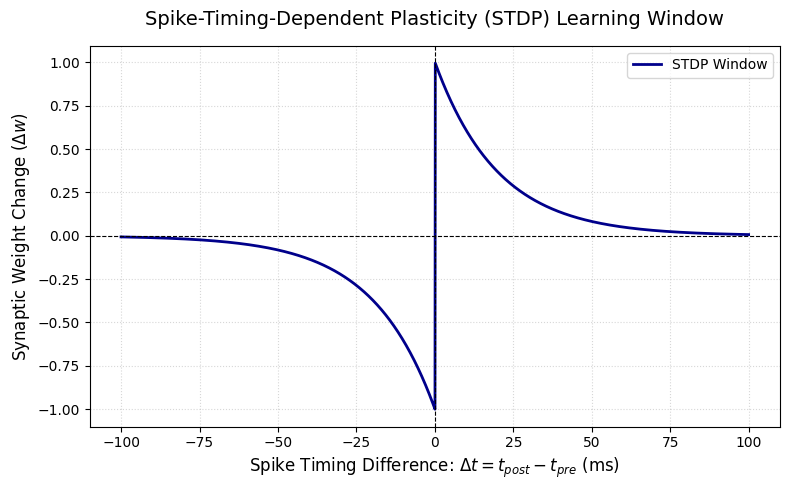

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# dt represents t_post - t_pre (in milliseconds)
dt = np.arange(-100, 100, 0.1)

# Standard STDP parameters
A_p = 1.0
A_n = -1.0
tau_p = 20.0
tau_n = 20.0

# STDP learning window
dw = np.where(dt >= 0, A_p * np.exp(-dt / tau_p), A_n * np.exp(dt / tau_n))




# AI PLOTTING CODE

# Plotting the improved STDP curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(dt, dw, label='STDP Window', color='darkblue', linewidth=2)

# Add visual guidelines
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax.axvline(0, color='black', linestyle='--', linewidth=0.8)

# Labels and styling
ax.set_title('Spike-Timing-Dependent Plasticity (STDP) Learning Window', fontsize=14, pad=15)
ax.set_xlabel(r'Spike Timing Difference: $\Delta t = t_{post} - t_{pre}$ (ms)', fontsize=12)
ax.set_ylabel(r'Synaptic Weight Change ($\Delta w$)', fontsize=12)
ax.grid(True, which='both', linestyle=':', alpha=0.5)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
# Idea for experiment to show learning
# 1. initialize all weights
# 2. feed random time signals as the pre-synaptic firing
# 3. have the post-synaptic be these time shifted
# We'd expect largest weight connection to be between neuron with the smallest positive time shift
# and largest negative to be smallest positive time shift

N = 10 # number of neurons in pre and post-synaptic layer (N*N total neurons)

W = np.ones([N, N])

